## Source


--------- Generation 1 ---------

Dados da geração 1 : {'avg': 182.99525828211364, 'min': 148.91434981792156, 'max': 227.82544744003482}
[[-0.5379529462078372, 2.8488283278000415, -1.027954179474798, 3.998598176914527, 2.51622258798517, -2.034911961742465, 0.010696326745840423, -2.8537108980570514, 1.307725763615176, -1.1143516514706397]]
[-0.28, 3.25, 1.16, 1.94, 0.06, 0.24, 1.47, -4.84, 3.71, 2.17]

Best individual: Davi Lucas Nunes, Genes: [-0.28, 3.25, 1.16, 1.94, 0.06, 0.24, 1.47, -4.84, 3.71, 2.17],Fitness: 111.23721988140548, SumEvaluate: 8.879999999999999

--------- Generation 2 ---------

Dados da geração 2 : {'avg': 163.1012272668395, 'min': 111.23721988140548, 'max': 204.57219517288326}
[[-0.5379529462078372, 2.8488283278000415, -1.027954179474798, 1.6289590701480758, -1.252994985744932, -2.034911961742465, 0.010696326745840423, -2.8537108980570514, 1.307725763615176, -1.1143516514706397]]
[-0.28, 3.25, 1.16, 1.94, 0.06, 0.24, 1.47, -4.84, 3.71, 2.17]

Best individual: Davi

,Generation,Best,Mean,Minimum,Maximum
0,1.0,227.825447,182.995258,148.914350,227.825447
1,2.0,204.572195,163.101227,111.237220,204.572195
2,3.0,192.978512,139.100199,100.273247,192.978512
3,4.0,168.143096,120.022853,94.647572,168.143096
4,5.0,125.889123,107.806921,90.864875,125.889123
...,...,...,...,...,...
95,96.0,41.104438,22.570335,21.338205,41.104438
96,97.0,47.185101,22.779059,21.338205,47.185101
97,98.0,47.549860,22.648788,21.338205,47.549860
98,99.0,21.338205,21.338205,21.338205,21.338205


,Generation,Nome,Fitness,FitnessRastrigin,FitnessSum
0,1,Davi Lucas Nunes,111.237220,139.296877,8.88
1,2,Davi Lucas Nunes,100.273247,139.296877,8.88
2,3,Kaique Nogueira,94.647572,205.298718,-8.48
3,4,Davi Lucas Nunes,90.864875,139.296877,8.88
4,5,Davi Lucas Nunes,90.864875,139.296877,8.88
...,...,...,...,...,...
95,96,Davi Lucas Nunes,21.338205,139.296877,8.88
96,97,Davi Lucas Nunes,21.338205,139.296877,8.88
97,98,Davi Lucas Nunes,21.338205,139.296877,8.88
98,99,Davi Lucas Nunes,21.338205,139.296877,8.88


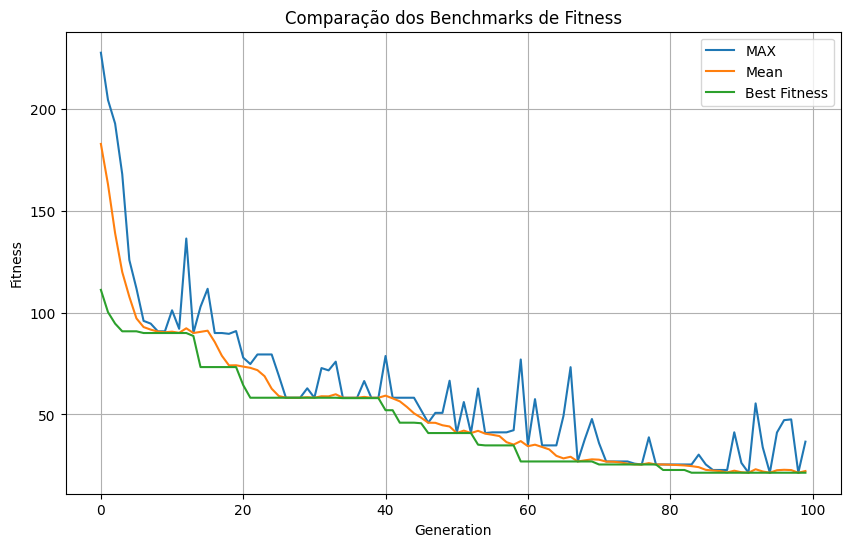

In [1]:
import random
from deap import base, creator, tools, algorithms
import numpy as np
import pandas as pd
from faker import Faker
import matplotlib.pyplot as plt
import json

# Faker for names
fake = Faker(['en_US','pt_BR','it_IT'])

used_names = set()

def generate_unique_name():
    while True:
        name = fake.name()
        if name not in used_names:
            used_names.add(name)
            return name
        
def initIndividual(genes):
    # Generate random genes of desired length
    genes = [random.randint(0,1) for _ in range(10)]
    return creator.Individual(genes=genes, name=generate_unique_name)


# Individual generator that includes unique name assignment
def create_unique_individual():
    individual = toolbox.individual()
    individual.genes = [round(random.uniform(-5,5),2) for _ in range(10)]
    individual.name = generate_unique_name()
    return individual

def repopulate_with_elite(population, elite_individuals, elite_size):
    """
    Substitui os indivíduos menos aptos da população atual pelos melhores indivíduos (elite).
    """
    # Ordena a população atual pelo fitness (do pior para o melhor)
    sorted_population = sorted(population, key=lambda ind: ind.fitness.values, reverse=True)
    
    # Substitui os menos aptos pelos indivíduos elite
    sorted_population[:elite_size] = elite_individuals[:elite_size]
    
    return sorted_population

def remove_and_replace_duplicates(population):
    # Armazena indivíduos únicos baseando-se em nome e valor de fitness.
    unique_combinations = set()
    new_population = []
    
    for ind in population:
        # Avalia o fitness se ainda não foi avaliado.
        if not ind.fitness.valid:
            ind.fitness.values = toolbox.evaluate(ind)
        
        # Cria uma chave única baseando-se no nome e fitness.
        key = (ind.name, ind.fitness.values)
        
        if key not in unique_combinations:
            unique_combinations.add(key)
            new_population.append(ind)
        else:
            # Gera e avalia novos indivíduos até encontrar um único.
            unique_found = False
            while not unique_found:
                new_ind = create_unique_individual()
                new_ind.fitness.values = toolbox.evaluate(new_ind)
                new_key = (new_ind.name, new_ind.fitness.values)
                
                if new_key not in unique_combinations:
                    unique_combinations.add(new_key)
                    new_population.append(new_ind)
                    unique_found = True
                    
    return new_population



def evaluateInd(individual):
    return sum(individual),  

def rastrigin_fitness(individual):
    A = 10
    n = len(individual.genes)
    return A*n + sum(x**2 - A * np.cos(2 * np.pi * x) for x in individual.genes),

def sum_fitness(individual):
    return sum(individual.genes),

# Rastrigin function
def rastrigin(individual):
    A = 10
    n = len(individual)
    return A*n + sum([(x**2 - A * np.cos(2 * np.pi * x)) for x in individual]),

def evaluate_composite(individual):
    # Avalia o indivíduo usando a função de Rastrigin
    fitness_rastrigin = rastrigin_fitness(individual)[0]
    
    # Avalia o indivíduo usando a função de soma
    fitness_sum = sum_fitness(individual)[0]
    
    # Retorna os resultados como um dicionário para facilitar o acesso
    return {'rastrigin_genes': fitness_rastrigin, 'sum': fitness_sum}

def rosenbrock(x, y):
    return (1 - x)**2 + 100 * (y - x**2)**2

# Constantes
POP_SIZE = 20  # Tamanho da população
CROSSOVER = 0.9  # Probabilidade de crossover
MUTATION = 0.05  # Probabilidade de mutação
GENERATIONS = 100  # Número de gerações


best_population = []
dados = {}

# Assuming you have already created the Fitness and Individual classes with DEAP
creator.create("FitnessMin", base.Fitness, weights=(-1.0,))
creator.create("Individual", list, fitness=creator.FitnessMin)

toolbox = base.Toolbox()

# Attribute generator
# Adjust attribute generator for float values in the range [-5, 5]
toolbox.register("attr_float", random.uniform, -5, 5)
toolbox.register("individual", tools.initRepeat, creator.Individual, toolbox.attr_float, n=10)


toolbox.register("population", tools.initRepeat, list, create_unique_individual, n=10)


# Evaluation
toolbox.register("evaluate", rastrigin)
toolbox.register("evaluate_rastrigin", rastrigin_fitness)
toolbox.register("evaluate_sum", sum_fitness)

# Genetic operators
toolbox.register("mate", tools.cxTwoPoint)
toolbox.register("mutate", tools.mutGaussian, mu=0, sigma=1, indpb=0.1)
toolbox.register("select", tools.selTournament, tournsize=3)

# Elitism
IND_ELITE = tools.HallOfFame(1)




# Statistics
stats = tools.Statistics(key=lambda ind: ind.fitness.values[0])
stats.register("avg", np.mean)
stats.register("min", np.min)
stats.register("max", np.max)

def main():
    pop = toolbox.population(n=POP_SIZE)
   

    # Initialize fitness, generate names, and collect data
    fitnesses = list(map(toolbox.evaluate, pop))
    for ind, fit in zip(pop, fitnesses):

        #Funcoes objetivos
        try:
            fitness_results = evaluate_composite(ind)
            ind.rastrigin_fitness = fitness_results['rastrigin_genes']  # Armazenamento personalizado
            ind.sum_fitness = fitness_results['sum']
        except:
            print('\nerro')

        #Dados individuo
        ind.fitness.values = fit
        #print("\n\nDEBUG",ind.name, fit)
        ind.name = fake.name()

    df = pd.DataFrame(columns=["Generation","Best", "Mean", "Minimum", "Maximum"])

    # Evolution
    for gen in range(GENERATIONS):
        dados = {}
        print(f"\n--------- Generation {gen+1} ---------")

        # Imprime a população
        for ind_num, ind in enumerate(pop):
            pass
            #print(f"Indivíduo {ind_num}: {ind.name}, Fitness: {ind.fitness.values}")

        # Elitism (update HOF and select best next generation)
        offspring = toolbox.select(pop, k=len(pop))
        offspring = [toolbox.clone(ind) for ind in offspring]

        # Collect statistics
        stats_data = stats.compile(pop)
        print("\nDados da geração", gen+1, ":", stats_data)
        df.loc[gen] = [gen+1, stats_data["max"], stats_data["avg"], stats_data["min"], stats_data["max"]]

        # Crossover and mutation
        for child1, child2 in zip(offspring[::2], offspring[1::2]):
            if random.random() < CROSSOVER:
                toolbox.mate(child1, child2)
                del child1.fitness.values
                del child2.fitness.values
        for mutant in offspring:
            if random.random() < MUTATION:
                toolbox.mutate(mutant)
                del mutant.fitness.values

        # Evaluate invalid individuals
        invalid_ind = [ind for ind in offspring if not ind.fitness.valid]
        fitnesses = map(toolbox.evaluate, invalid_ind)
        for ind, fit in zip(invalid_ind, fitnesses):
            ind.fitness.values = fit
            
        
        #Selecionando o conjunto elite
        #pop = tools.selBest(pop + offspring, k=POP_SIZE)
        IND_ELITE.update(offspring)
        print(IND_ELITE)
        print(IND_ELITE.items[0].genes)

        print(f"\nBest individual: {IND_ELITE.items[0].name}, Genes: {IND_ELITE.items[0].genes},Fitness: {IND_ELITE.items[0].fitness.values[0]}, SumEvaluate: {sum(IND_ELITE.items[0].genes)}")
        #df['Name'] = hof.items[0].name  
        dados["Generation"] = gen+1
        dados["Nome"] = IND_ELITE.items[0].name
        dados["Fitness"] = IND_ELITE.items[0].fitness.values[0]
        
        
        try:
            dados["FitnessRastrigin"] = IND_ELITE.items[0].rastrigin_fitness
            dados["FitnessSum"] = IND_ELITE.items[0].sum_fitness

        except:
            print('\n\nerro 2 ')
        best_population.append(dados)
    
        pop[:] = offspring



    # Results and plot
    display(df)
    df.to_excel("./results.xlsx")
    best_population_df = pd.read_json(
        json.dumps(best_population),
        orient="records"

    )
    display(best_population_df)

  
    
    #plot
    plt.figure(figsize=(10, 6))
    plt.plot(df["Best"], label="MAX")
    plt.plot(df["Mean"], label="Mean")
    plt.plot(best_population_df["Fitness"], label="Best Fitness")
    #plt.plot(best_population_df["FitnessRastrigin"], label="Fitness Rastrigin")
    plt.xlabel("Generation")
    plt.ylabel("Fitness")
    plt.legend()
    plt.title('Comparação dos Benchmarks de Fitness')
    plt.grid(True)

    plt.show()

if __name__ == "__main__":
    main()

c:\Users\PedroVictorRodrigues\AppData\Local\Programs\Python\Python311\Lib\site-packages\deap\creator.py:185: RuntimeWarning: A class named 'FitnessMin' has already been created and it will be overwritten. Consider deleting previous creation of that class or rename it.
  warnings.warn("A class named '{0}' has already been created and it "
c:\Users\PedroVictorRodrigues\AppData\Local\Programs\Python\Python311\Lib\site-packages\deap\creator.py:185: RuntimeWarning: A class named 'Individual' has already been created and it will be overwritten. Consider deleting previous creation of that class or rename it.
  warnings.warn("A class named '{0}' has already been created and it "


AttributeError: 'tuple' object has no attribute 'fitness'

## Solid

In [ ]:
import numpy as np

class MathOperations:
    def rastrigin(self, individual):
        A = 10
        n = len(individual)
        return A * n + sum([(x**2 - A * np.cos(2 * np.pi * x)) for x in individual]),


In [ ]:
from deap import base, creator, tools
import random
from faker import Faker

class DataPreparation:
    def __init__(self, pop_size):
        self.pop_size = pop_size
        self.used_names = set()
        self.fake = Faker()

    def generate_unique_name(self):
        while True:
            name = self.fake.name()
            if name not in self.used_names:
                self.used_names.add(name)
                return name

    

In [ ]:
from deap import algorithms

class AlgoritmoEvolutivo:
    def __init__(self, toolbox, math_operations):
        self.toolbox = toolbox
        self.toolbox.register("evaluate", math_operations.rastrigin)
        self.toolbox.register("mate", tools.cxTwoPoint)
        self.toolbox.register("mutate", tools.mutGaussian, mu=0, sigma=1, indpb=0.05)
        self.toolbox.register("select", tools.selTournament, tournsize=3)
        self.setup_deap()


    def create_individual(self, individual_creator):
        genes = [random.uniform(-5.12, 5.12) for _ in range(10)]
        name = self.generate_unique_name()
        return individual_creator(genes=genes, name=name)

    def setup_deap(self):
        creator.create("FitnessMax", base.Fitness, weights=(1.0,))
        creator.create("Individual", list, fitness=creator.FitnessMax)

        self.toolbox = base.Toolbox()
        self.toolbox.register("attr_float", random.uniform, -5.12, 5.12)
        self.toolbox.register("individual", tools.initIterate, creator.Individual,
                              lambda: [self.toolbox.attr_float() for _ in range(10)])
        self.toolbox.register("population", tools.initRepeat, list, self.toolbox.individual, n=self.pop_size)


    def run(self, ngen=100, cxpb=0.9, mutpb=0.05):
        pop = self.toolbox.population()
        hof = tools.HallOfFame(1)
        stats = tools.Statistics(lambda ind: ind.fitness.values)
        stats.register("avg", np.mean)
        stats.register("min", np.min)
        stats.register("max", np.max)

        algorithms.eaSimple(pop, self.toolbox, cxpb, mutpb, ngen, stats=stats, halloffame=hof)

        return pop, stats, hof
